In [1]:
pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd

df = pd.read_csv("StudentPerformance.csv")

# a. Load and inspect the dataset. 
# Load the dataset using Pandas. 
# Display the first five rows,
print("First Five rows:") 
print(df.head())
#number of rows and columns,
print("\nDataset Shape:")
print(df.shape) 

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# column names, 
print("\nColumn Names:")
print(df.columns)
# data types, and
print("\nData Types:")
print(df.dtypes) 
# missing value count for each column.
print("\nMissing values")
print(df.isnull().sum())

First Five rows:
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  

Dataset Shape:
(136, 8)

Number of Rows: 136
Number of Columns: 8

Column Names:
Index(['gender', 'race/ethnicity', 'parental level of educat

In [5]:
# b. Explore the data using NumPy and Pandas. 
# Select at least two numerical columns.
import pandas as pd

df = pd.read_csv("StudentPerformance.csv")

math = df["math score"]
reading = df["reading score"]
writing = df["writing score"]

# Use NumPy to calculate their mean,

print("Math Mean:", math.mean())
print("Reading Mean:", reading.mean())
print("Writing Mean:", writing.mean())

# minimum, and

print("Math Minimum:", math.min())
print("Reading Minimum:", reading.min())
print("Writing Minimum:", writing.min())

# maximum.

print("Math Maximum:", math.max())
print("Reading Maximum:", reading.max())
print("Writing Maximum:", writing.max())

# Use Pandas to display summary statistics,

print(df.describe())

# sort the data by one relevant column, and

sorted_df = df.sort_values(
    by="math score",
    ascending=False
)

print(sorted_df.head())

# show the first five rows after sorting.

print("Top 5 Students:")
print(sorted_df.head(5))

# Display bottom five students

print("Bottom 5 Students:")
print(df.sort_values(by="math score").head(5))


Math Mean: 63.74264705882353
Reading Mean: 66.99264705882354
Writing Mean: 65.69117647058823
Math Minimum: 0
Reading Minimum: 17
Writing Minimum: 10
Math Maximum: 99
Reading Maximum: 100
Writing Maximum: 100
       math score  reading score  writing score
count  136.000000     136.000000     136.000000
mean    63.742647      66.992647      65.691176
std     16.372514      16.338320      16.989982
min      0.000000      17.000000      10.000000
25%     53.000000      55.750000      54.000000
50%     65.000000      69.000000      67.500000
75%     75.000000      79.250000      76.000000
max     99.000000     100.000000     100.000000
     gender race/ethnicity parental level of education     lunch  \
114  female        group E           bachelor's degree  standard   
104    male        group C                some college  standard   
34     male        group E                some college  standard   
121    male        group B          associate's degree  standard   
2    female        g

In [6]:
# c. Clean and preprocess the data. 
# Check for duplicate rows and 

import pandas as pd

df = pd.read_csv("StudentPerformance.csv")

print("Duplicate Rows:")
print(df.duplicated().sum())

# Remove duplicate rows

df = df.drop_duplicates()

# missing values.

print(df.isnull().sum())

# Apply a suitable method to handle them and briefly explain your choices. 


# Identify any categorical columns that need encoding.

print(df.select_dtypes(include="object").columns)

df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)

print(df_encoded.head())

# Check for possible outliers in at least one numerical column.

Q1 = df["math score"].quantile(0.25)
Q3 = df["math score"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["math score"] < lower) |
    (df["math score"] > upper)
]

print("Outliers:")
print(outliers)





Duplicate Rows:
0
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64
Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course'],
      dtype='object')
   math score  reading score  writing score  gender_male  \
0          72             72             74            0   
1          69             90             88            0   
2          90             95             93            0   
3          47             57             44            1   
4          76             78             75            1   

   race/ethnicity_group B  race/ethnicity_group C  race/ethnicity_group D  \
0                       1                       0                       0   
1                       0                       1         

In [7]:
# d. Identify features and target. 

X = df[
    ["reading score",
     "writing score",
     "gender",
     "test preparation course",
     "lunch"]
]

y = df["math score"]

print("Features:")
print(X.head()) # input features

print("Target:")
print(y.head())  # Target Features

# State the target column you would use for prediction and 
# identify at least three possible features. 
# Briefly explain why the target and features are appropriate for the problem.


Features:
   reading score  writing score  gender test preparation course         lunch
0             72             74  female                    none      standard
1             90             88  female               completed      standard
2             95             93  female                    none      standard
3             57             44    male                    none  free/reduced
4             78             75    male                    none      standard
Target:
0    72
1    69
2    90
3    47
4    76
Name: math score, dtype: int64


In [8]:
# e. Perform exploratory data analysis. 
# Calculate at least two descriptive statistics, such as median,

print("Median:", df["math score"].median())

# mode

print("Mode:", df["math score"].mode())

# variance, or

print("Variance:", df["math score"].var())

# standard deviation.

print("Standard Deviation:", df["math score"].std())

# Identify one pattern or relationship between variables. 
# If you calculate correlation, briefly explain what it suggests.
print(df[
    ["math score", "reading score", "writing score"]
].corr())



Median: 65.0
Mode: 0    58
Name: math score, dtype: int64
Variance: 268.05920479302836
Standard Deviation: 16.372513698055908
               math score  reading score  writing score
math score       1.000000       0.872768       0.876212
reading score    0.872768       1.000000       0.965959
writing score    0.876212       0.965959       1.000000


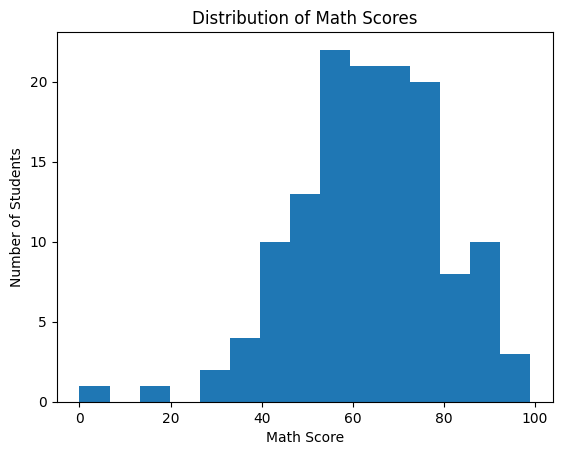

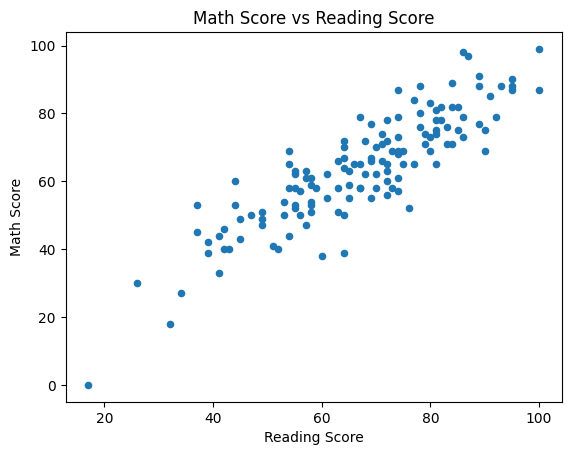

In [9]:
# Create Visulizations

# Pandas can create basic charts using its built-in plotting functions, 
# but Matplotlib is used to render and customize them.

# Chart 1 : Histogram

df["math score"].plot(
    kind="hist",
    bins=15,
    title="Distribution of Math Scores"
)

import matplotlib.pyplot as plt

plt.xlabel("Math Score")
plt.ylabel("Number of Students")
plt.show()

# Chart 2 : Scatter plot

df.plot(
    kind="scatter",
    x="reading score",
    y="math score",
    title="Math Score vs Reading Score"
)

plt.xlabel("Reading Score")
plt.ylabel("Math Score")
plt.show()
